# PCOS Likelihood Classifier
**Goal:** To predict whether a patient has PCOS (Y/N) and give a probability ("likelihood") for each patient.

**Plan**
1. Load and clean the data
2. Data exploration (class balance, which features matter)
3. Train three models and compare them fairly with cross-validation
4. Test the best one on data it has never seen
5. Repeat without ultrasound features, because those are used to diagnose PCOS and can make the task too easy


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (classification_report, confusion_matrix, ConfusionMatrixDisplay,
                             roc_auc_score, RocCurveDisplay)

RANDOM_STATE = 42
DATA_PATH = "PCOS_data.csv"


## 1. Load and clean
The raw file has messy column names, two ID columns, and an empty extra column. We fix those.

In [2]:
df = pd.read_csv("PCOS_data.csv")
print("Raw shape:", df.shape)

# Tidy column names: remove stray spaces and awkward characters
df.columns = (df.columns.str.strip()
                         .str.replace(r"\s+", " ", regex=True))

# Drop ID columns and the empty column
df = df.drop(columns=["Sl. No", "Patient File No."] + [c for c in df.columns if c.startswith("Unnamed")])

# Fix a typo in a column name and give the target a simple name
df = df.rename(columns={"Marraige Status (Yrs)": "Marriage Status (Yrs)", "PCOS (Y/N)": "PCOS"})

# Make sure every column is numeric (a few can be read as text in this dataset)
df = df.apply(pd.to_numeric, errors="coerce")

print("Clean shape:", df.shape)
print("Missing values per column:")
print(df.isna().sum()[df.isna().sum() > 0])


Raw shape: (541, 45)
Clean shape: (541, 42)
Missing values per column:
Marriage Status (Yrs)    1
II beta-HCG(mIU/mL)      1
AMH(ng/mL)               1
Fast food (Y/N)          1
dtype: int64


## 2. Explore
How many patients have PCOS, and which features move with it?

PCOS
0    364
1    177
Name: count, dtype: int64
PCOS
0    67.3 %
1    32.7 %
Name: proportion, dtype: object


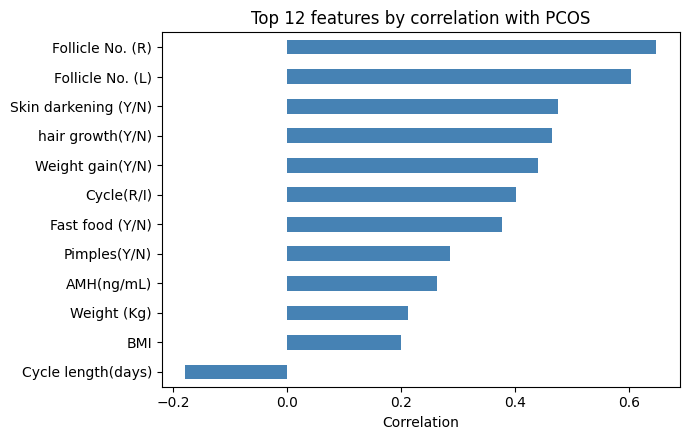

In [3]:
print(df["PCOS"].value_counts())
print((df["PCOS"].value_counts(normalize=True) * 100).round(1).astype(str) + " %")

corr = df.corr(numeric_only=True)["PCOS"].drop("PCOS").sort_values(key=abs, ascending=False)
top = corr.head(12)

plt.figure(figsize=(7, 4.5))
top[::-1].plot(kind="barh", color="steelblue")
plt.title("Top 12 features by correlation with PCOS")
plt.xlabel("Correlation")
plt.tight_layout()
plt.show()


**How to read this:** a bar to the right means the feature is higher in PCOS patients, to the left means lower. Expect follicle counts, skin darkening, hair growth, weight gain and cycle irregularity near the top.

## 3. Choose the features
Two versions of the problem:

- **Set A (all features):** includes ultrasound follicle measurements. Likely very accurate, but doctors use these to diagnose PCOS, so it is partly "predicting the answer from the answer".
- **Set B (no ultrasound):** only symptoms, body measurements and blood tests. A more realistic screening tool.

In [4]:
ultrasound_cols = ["Follicle No. (L)", "Follicle No. (R)",
                   "Avg. F size (L) (mm)", "Avg. F size (R) (mm)", "Endometrium (mm)"]

y = df["PCOS"]
X_all = df.drop(columns="PCOS")
X_no_us = X_all.drop(columns=ultrasound_cols)

# Keep 20% of patients aside as a final test. Stratify keeps the PCOS ratio the same in both parts.
idx_train, idx_test = train_test_split(df.index, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
y_train, y_test = y.loc[idx_train], y.loc[idx_test]


## 4. Compare models
We use **5-fold cross-validation** on the training data. Each model gets the same preprocessing (fill gaps with the median, scale numbers), and the two that can handle imbalance are told to weight the PCOS class more.

Metrics:
- **Recall:** of the people who truly have PCOS, how many did we catch? (most important for screening)
- **Precision:** of the people we flagged, how many really have it?
- **ROC-AUC:** how well the model ranks PCOS patients above non-PCOS patients (1.0 perfect, 0.5 coin flip)

In [5]:
def make_models():
    prep = lambda: [("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())]
    return {
        "Logistic Regression": Pipeline(prep() + [("clf", LogisticRegression(max_iter=2000, class_weight="balanced"))]),
        "KNN":                 Pipeline(prep() + [("clf", KNeighborsClassifier(n_neighbors=7))]),
        "Random Forest":       Pipeline(prep() + [("clf", RandomForestClassifier(n_estimators=300, class_weight="balanced",
                                                                               random_state=RANDOM_STATE))]),
    }

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = ["accuracy", "precision", "recall", "f1", "roc_auc"]

def compare(X, label):
    rows = []
    for name, model in make_models().items():
        s = cross_validate(model, X.loc[idx_train], y_train, cv=cv, scoring=scoring)
        rows.append({"Features": label, "Model": name,
                     **{m: s[f"test_{m}"].mean() for m in scoring}})
    return pd.DataFrame(rows)

results = pd.concat([compare(X_all, "A: all features"),
                     compare(X_no_us, "B: no ultrasound")]).round(3)
results


,Features,Model,accuracy,precision,recall,f1,roc_auc
0,A: all features,Logistic Regression,0.866,0.773,0.844,0.806,0.931
1,A: all features,KNN,0.859,0.890,0.660,0.752,0.923
2,A: all features,Random Forest,0.884,0.911,0.724,0.804,0.953
0,B: no ultrasound,Logistic Regression,0.794,0.657,0.781,0.712,0.844
1,B: no ultrasound,KNN,0.822,0.794,0.610,0.688,0.867
2,B: no ultrasound,Random Forest,0.810,0.788,0.582,0.667,0.881


## 5. Final test on unseen patients


===== A: all features | Logistic Regression =====
              precision    recall  f1-score   support

     No PCOS       0.94      0.89      0.92        73
        PCOS       0.80      0.89      0.84        36

    accuracy                           0.89       109
   macro avg       0.87      0.89      0.88       109
weighted avg       0.90      0.89      0.89       109

ROC-AUC: 0.951
===== B: no ultrasound | Logistic Regression =====
              precision    recall  f1-score   support

     No PCOS       0.88      0.82      0.85        73
        PCOS       0.68      0.78      0.73        36

    accuracy                           0.81       109
   macro avg       0.78      0.80      0.79       109
weighted avg       0.82      0.81      0.81       109

ROC-AUC: 0.863


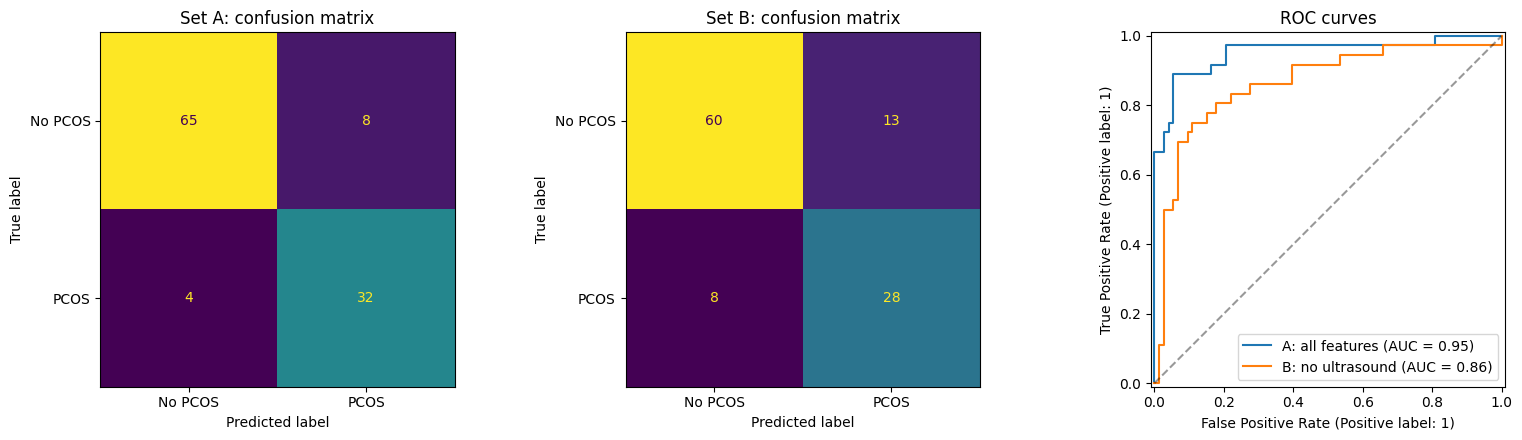

In [6]:
best_name = "Logistic Regression"

def final_test(X, label):
    model = make_models()[best_name]
    model.fit(X.loc[idx_train], y_train)
    pred = model.predict(X.loc[idx_test])
    proba = model.predict_proba(X.loc[idx_test])[:, 1]

    print(f"===== {label} | {best_name} =====")
    print(classification_report(y_test, pred, target_names=["No PCOS", "PCOS"]))
    print("ROC-AUC:", round(roc_auc_score(y_test, proba), 3))
    return model, pred, proba

model_A, pred_A, proba_A = final_test(X_all, "A: all features")
model_B, pred_B, proba_B = final_test(X_no_us, "B: no ultrasound")

fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
ConfusionMatrixDisplay(confusion_matrix(y_test, pred_A), display_labels=["No PCOS", "PCOS"]).plot(ax=ax[0], colorbar=False)
ax[0].set_title("Set A: confusion matrix")
ConfusionMatrixDisplay(confusion_matrix(y_test, pred_B), display_labels=["No PCOS", "PCOS"]).plot(ax=ax[1], colorbar=False)
ax[1].set_title("Set B: confusion matrix")
RocCurveDisplay.from_predictions(y_test, proba_A, name="A: all features", ax=ax[2])
RocCurveDisplay.from_predictions(y_test, proba_B, name="B: no ultrasound", ax=ax[2])
ax[2].plot([0, 1], [0, 1], "k--", alpha=0.4)
ax[2].set_title("ROC curves")
plt.tight_layout()
plt.show()


## Notes and limitations
- Only ~540 patients from one source, so results can swing between splits. Treat numbers as indicative, not clinical.
- Possible leakage: ultrasound features (Set A) overlap with the diagnosis itself.
- This is a personal model, **not** a medical diagnostic tool.
- Ideas to extend: hyperparameter tuning (GridSearchCV), a probability threshold chosen for higher recall, SHAP for explanations, repeated CV for steadier estimates.